In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
# read in data, then create dictionary to work with
# in increments of 10: 37 - 107, then 137, 150

frequencies = [37, 47, 57, 67, 77, 87, 97, 107, 137, 150]
data = {}

for freq in frequencies: 
    temp_df = pd.read_csv(f"{freq}k_freq.txt", sep =r"\s+") # utilize regex. why? 
    # print(temp_df)
    data[f"{freq}k"] = {"time": temp_df["time"], "potential_1": temp_df["potential_1"], "potential_2": temp_df["potential_2"]}



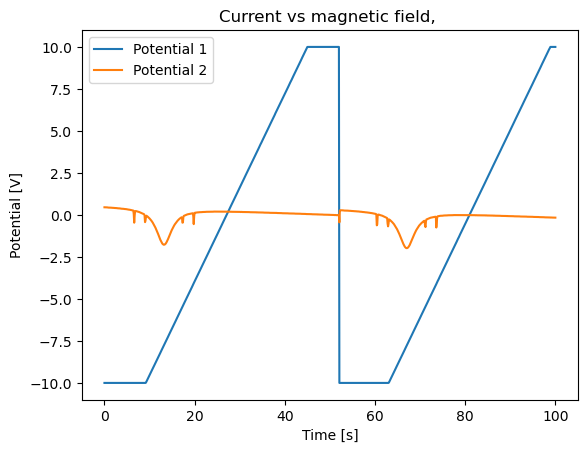

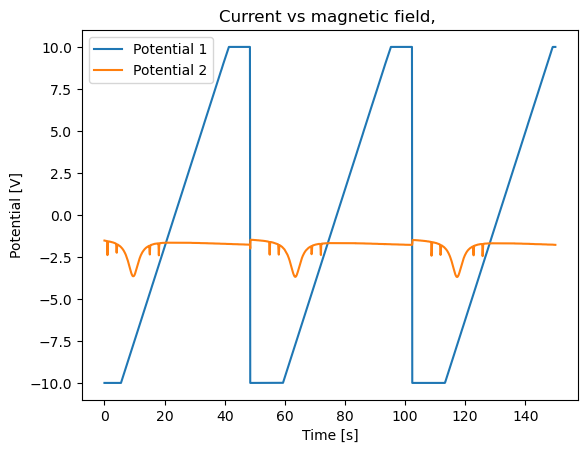

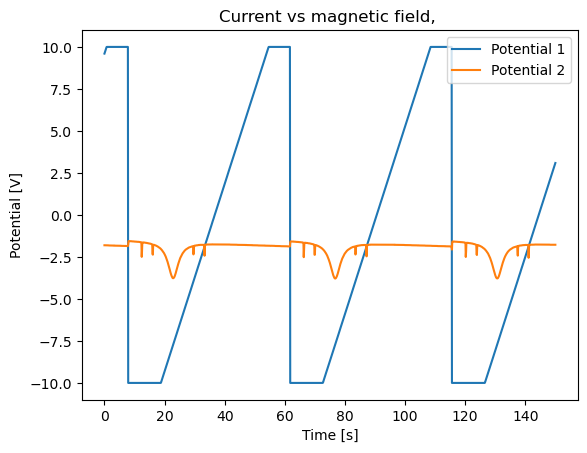

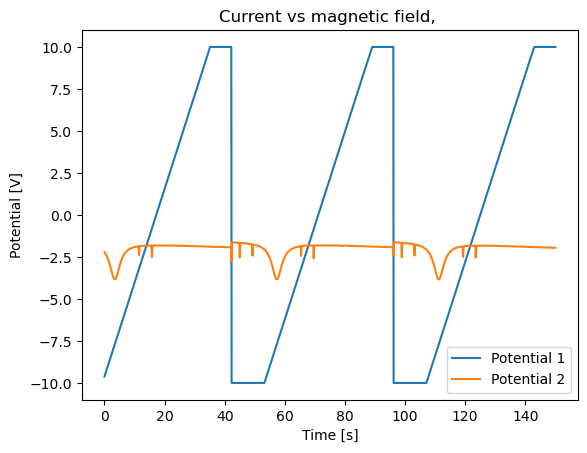

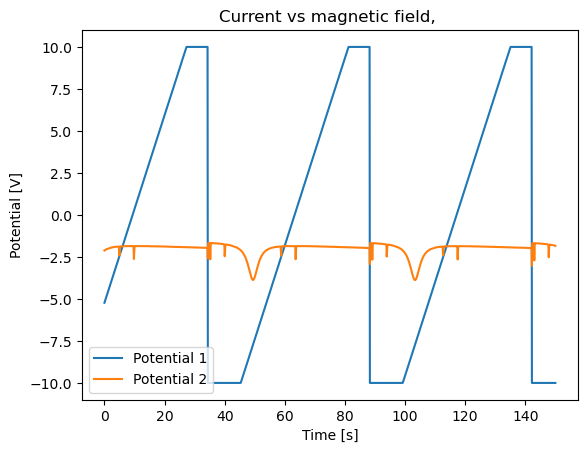

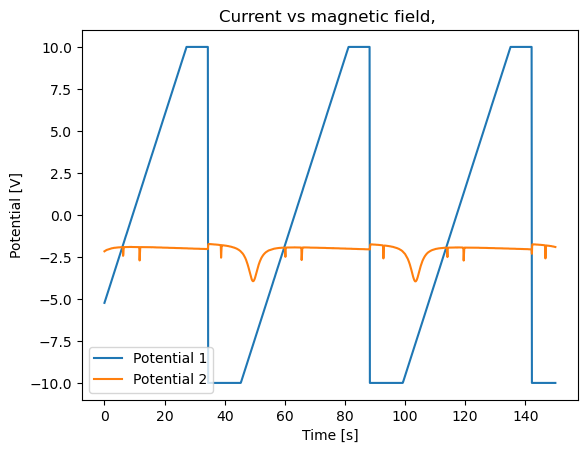

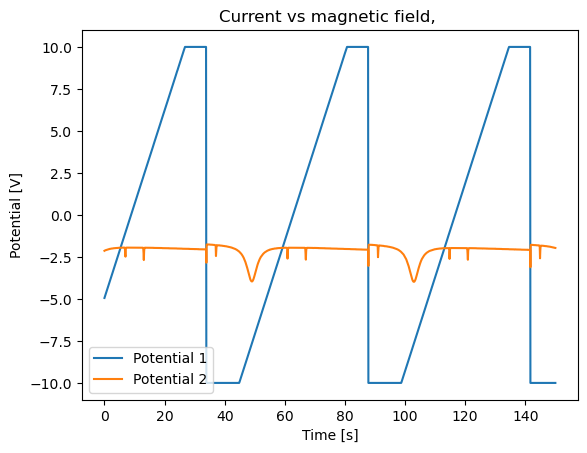

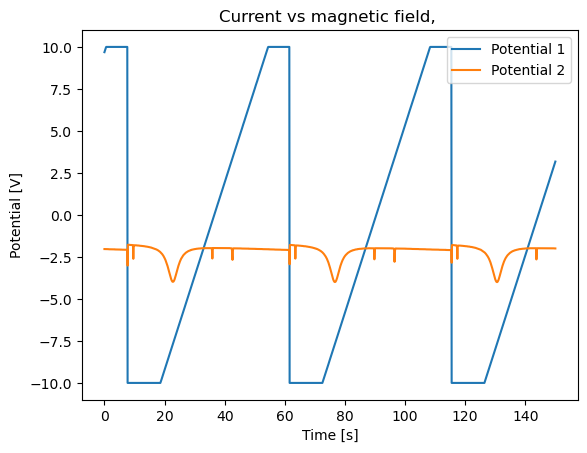

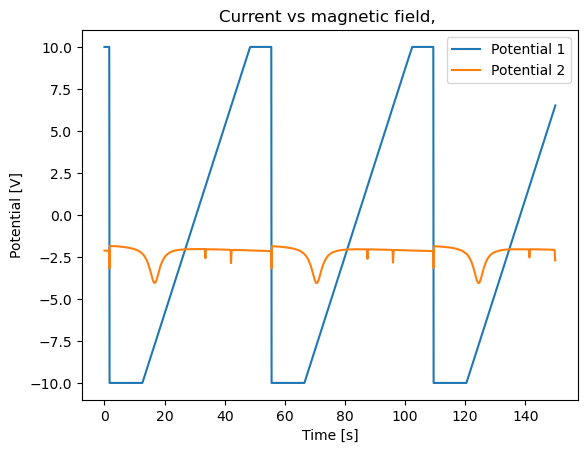

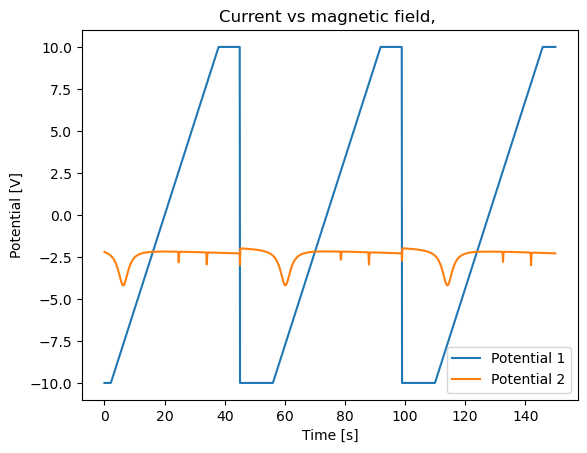

In [4]:
for freq in frequencies:
    fig, ax = plt.subplots()
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_1"], label = "Potential 1")
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_2"], label = "Potential 2")
    ax.legend()
    ax.set_title(f"Current vs magnetic field, ")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Potential [V]")

In [5]:
constant = 8.991e-3
resistance = 50 # ohms
turns = 11
mean_radius = 0.1639 # meters
N_over_R = turns/mean_radius


for freq in frequencies: 
    data[f"{freq}k"]["current"] = data[f"{freq}k"]["potential_1"]/resistance
    data[f"{freq}k"]["B_field"] = (8.991e-3)*(data[f"{freq}k"]["current"])*N_over_R

print(data["37k"]["B_field"])


0      -0.120685
1      -0.120685
2      -0.120685
3      -0.120685
4      -0.120685
          ...   
996     0.120681
997     0.120681
998     0.120681
999     0.120681
1000    0.120681
Name: potential_1, Length: 1001, dtype: float64


C:\Users\ariel\AppData\Local\Temp\ipykernel_14052\3899258520.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


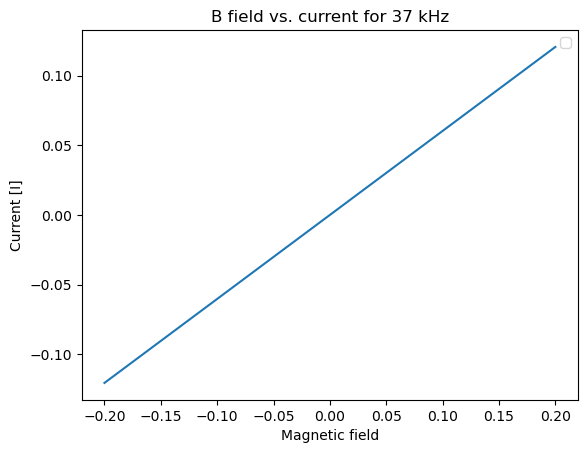

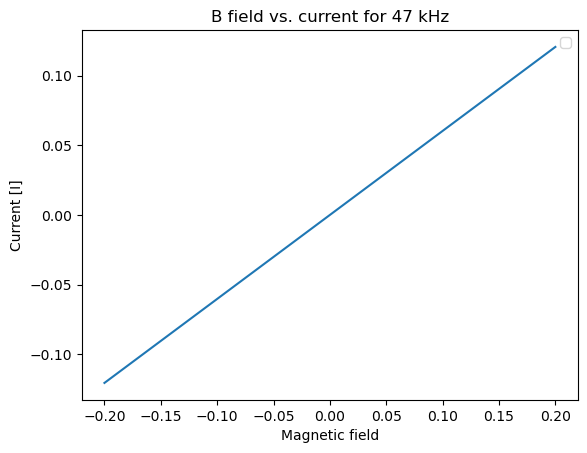

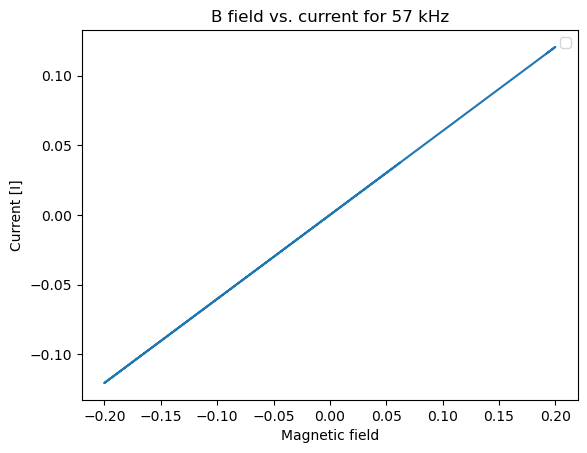

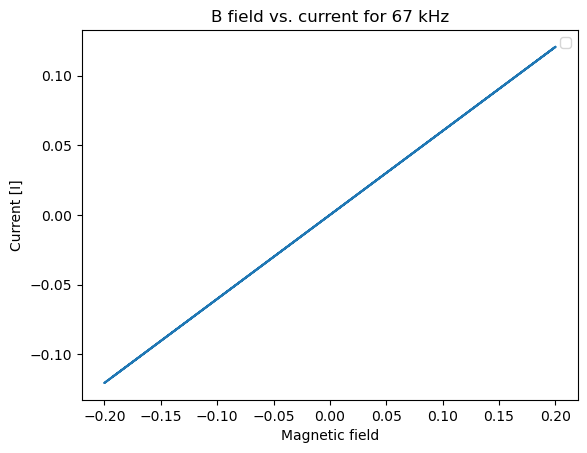

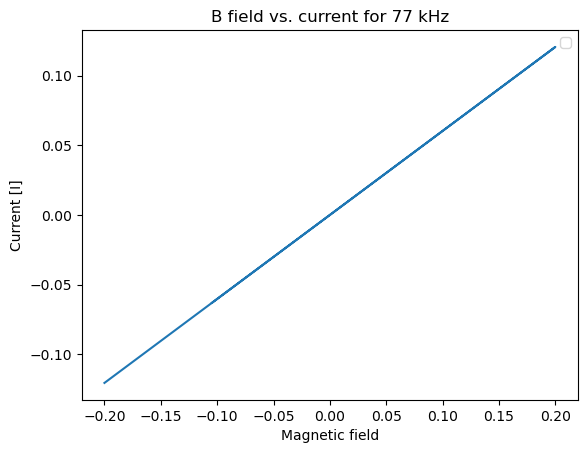

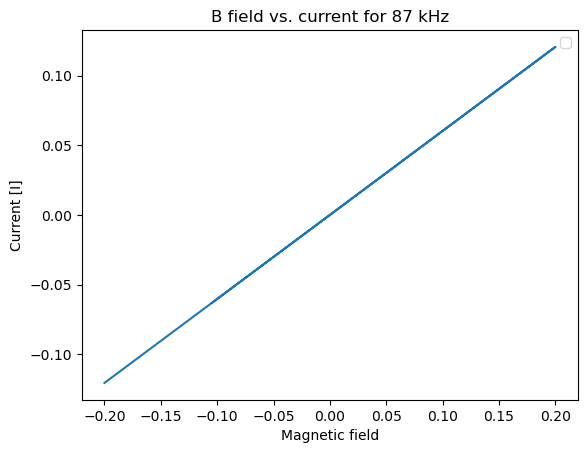

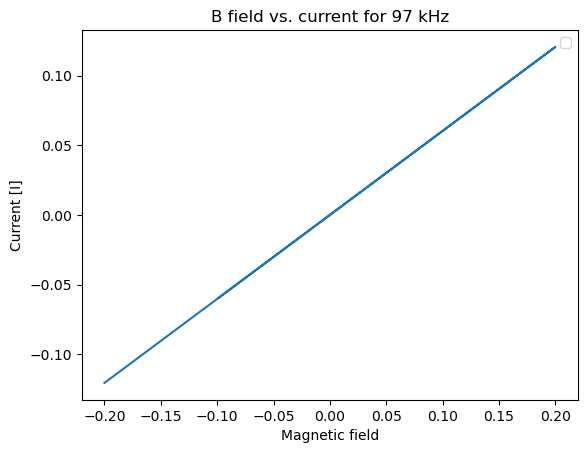

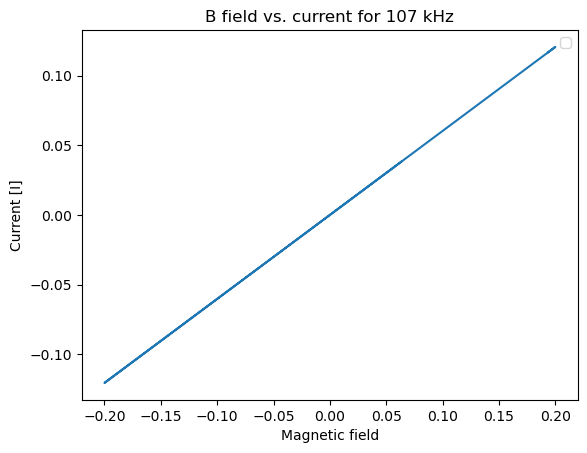

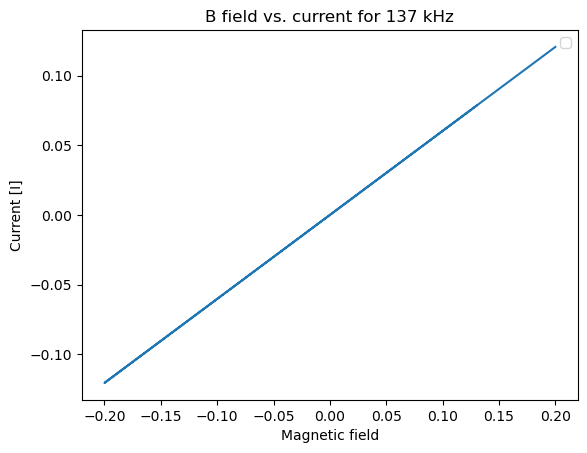

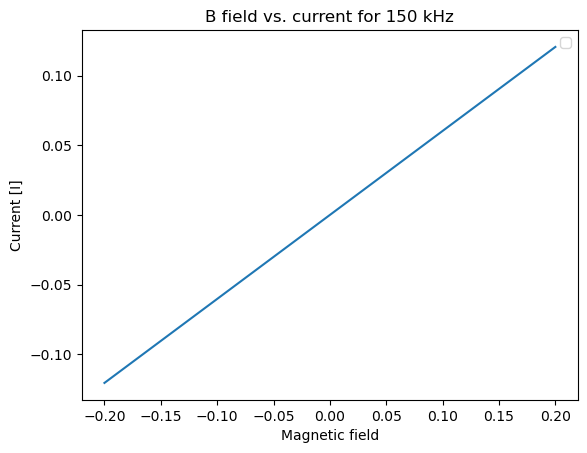

In [6]:
for freq in frequencies:
    fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["B_field"], label = "B_field")
    ax.plot(data[f"{freq}k"]["current"], data[f"{freq}k"]["B_field"])
    ax.legend()
    ax.set_title(f"B field vs. current for {freq} kHz")
    ax.set_xlabel("Magnetic field")
    ax.set_ylabel("Current [I]")

In [7]:
from sklearn.linear_model import LinearRegression
all_slopes = []
all_intercepts = []

for freq in frequencies:
    current_temp = data[f"{freq}k"]["current"]
    current_temp = current_temp.to_numpy().reshape(-1, 1) # -1 for determining the shape of the passed current_temp, 
                                                          # 1 is the amount of columns is reshapes to; for sklearn, one column per input
    B_field_temp = data[f"{freq}k"]["B_field"]
    B_field_temp = B_field_temp.to_numpy()
    # print(type(B_field_temp))
    fit = LinearRegression().fit(current_temp, B_field_temp)

    all_slopes.append(fit.coef_[0])
    all_intercepts.append(fit.intercept_)

    # fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["current"], data[f"{freq}k"]["B_field"], label = f"y = {fit.coef_[0]:0.3f}x + {fit.intercept_}")
    # ax.set_title(f"Magnetic field vs. current for {freq} Hz")
    # ax.set_xlabel("Magnetic field")
    # ax.set_ylabel("Current")
    # ax.grid()
    # ax.legend()

print(np.average(all_slopes))



ModuleNotFoundError: No module named 'sklearn'

In [8]:
from scipy.stats import linregress


all_slopes = []
all_intercepts = []
fit_errors = []

for freq in frequencies:
    current_temp = data[f"{freq}k"]["current"]
    current_temp = current_temp.to_numpy()
    B_field_temp = data[f"{freq}k"]["B_field"]
    B_field_temp = B_field_temp.to_numpy()
    # print(type(B_field_temp))
    fit = linregress(current_temp, B_field_temp)
    all_slopes.append(fit.slope)
    all_intercepts.append(fit.intercept)
    fit_errors.append(fit.stderr)
    print(f"{freq}k: slope = {fit.slope}, fit error = {fit.stderr}")


37k: slope = 0.6034228187919449, fit error = 1.3936852981389232e-09
47k: slope = 0.6034228187919479, fit error = 0.0
57k: slope = 0.6034228187919454, fit error = 0.0
67k: slope = 0.6034228187919457, fit error = 0.0
77k: slope = 0.603422818791945, fit error = 6.568799696582387e-10
87k: slope = 0.6034228187919466, fit error = 0.0
97k: slope = 0.6034228187919481, fit error = 0.0
107k: slope = 0.6034228187919463, fit error = 0.0
137k: slope = 0.6034228187919471, fit error = 9.289685619419123e-10
150k: slope = 0.6034228187919467, fit error = 0.0


In [9]:
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def gaussian_with_linear_bg(x, a, mu, sigma, c0, c1):
    return a * np.exp(-0.5((x-mu)/sigma)**2 + c0 + c1*x)

# x = data
# a = peak amplitude
# mu = peak location
# sigma = peak spread
# c0, c1: linear background

peaks, properties = find_peaks(y, prominence=50, width=2) 
# find_peaks returns the peak locations as an array, 
# as well as a dictionary of those peak properties

locations = []

for p in peaks:
    fitting_window = int(properties["widths"][list(peaks).index(p) * 2]) # have the fitting window be double the peak width
    low, high = max(p - w, 0), min(p + w, len(y)) # have the low and high fit guesses be the peak location +/- width
    p0 = [y[p], x[p], x[1] - x[0], y[low], 0] # inital guesses in the order of x, a, mu, sigma, c0, c1
    popt, pcov = curve_fit(gaussian_with_linear_bg, x[low:hi], y[low:hi], p0=p0)
    locations.append((popt[1], np.sqrt[1,1]))

print(locations)

<>:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
<>:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
C:\Users\ariel\AppData\Local\Temp\ipykernel_14052\4259227435.py:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
  return a * np.exp(-0.5((x-mu)/sigma)**2 + c0 + c1*x)


NameError: name 'y' is not defined

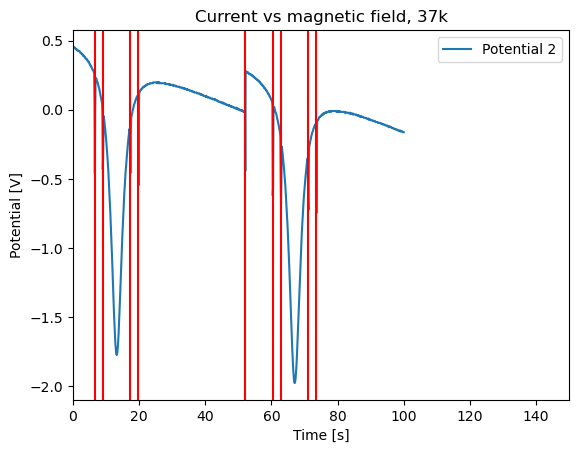

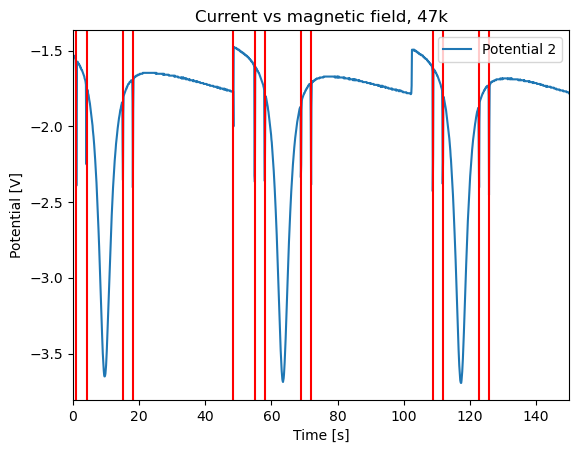

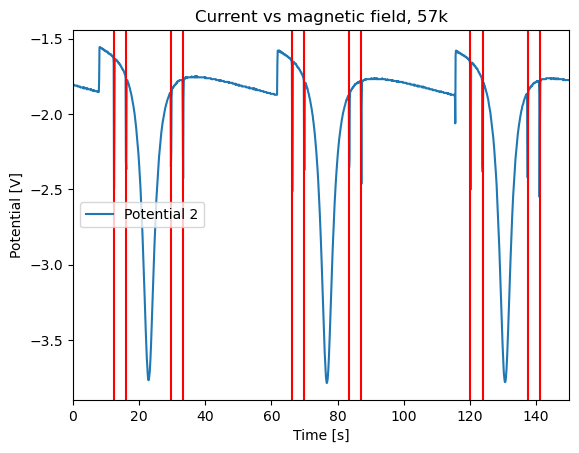

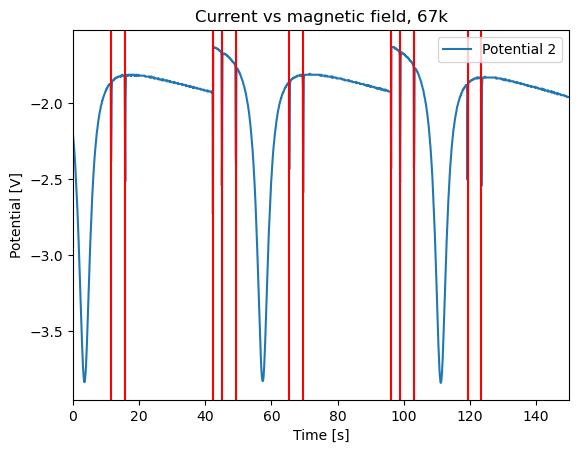

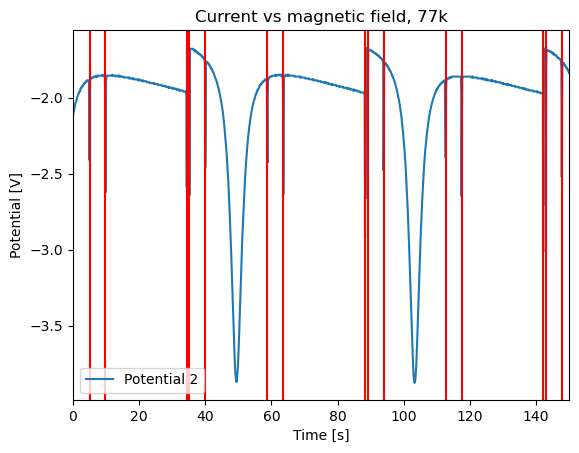

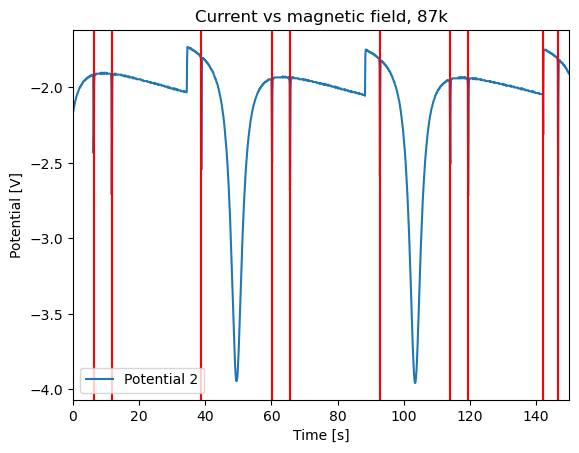

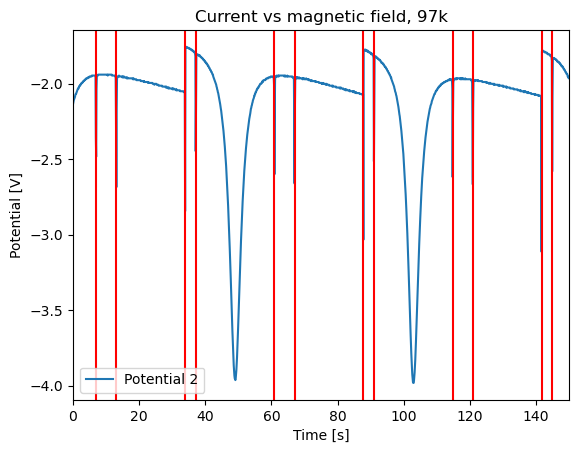

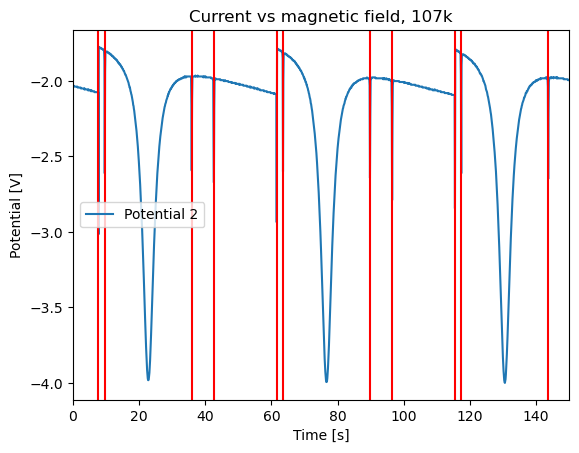

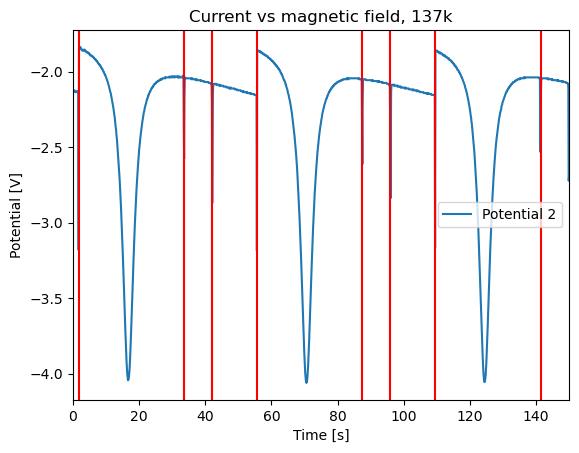

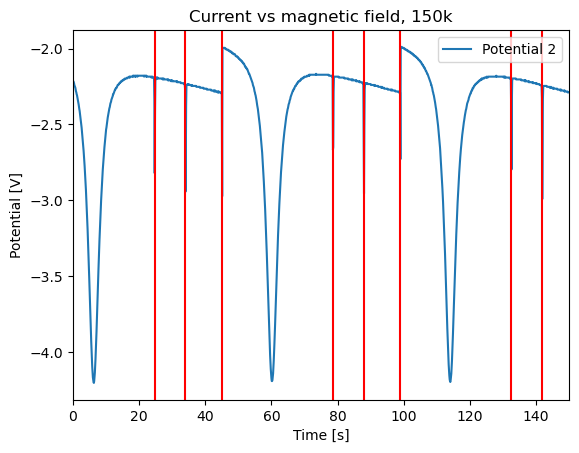

In [14]:
stored_currents = []
stored_frequencies = []

for freq in frequencies:
    data_temp = data[f"{freq}k"]["potential_2"]
    peaks, properties = find_peaks(-data_temp, prominence=0.3, width=(None, 10))
    # print(peaks)

    fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_1"], label = "Potential 1")
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_2"], label = "Potential 2")
    ax.legend()
    for p in peaks:
        ax.axvline(x = data[f"{freq}k"]["time"][p], color = "red")
    ax.set_title(f"Current vs magnetic field, {freq}k")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Potential [V]")
    ax.set_xlim(0,150)

    for p in peaks:
        stored_currents.append((data[f"{freq}k"]["current"][p])/resistance)
        stored_frequencies.append(freq)

    

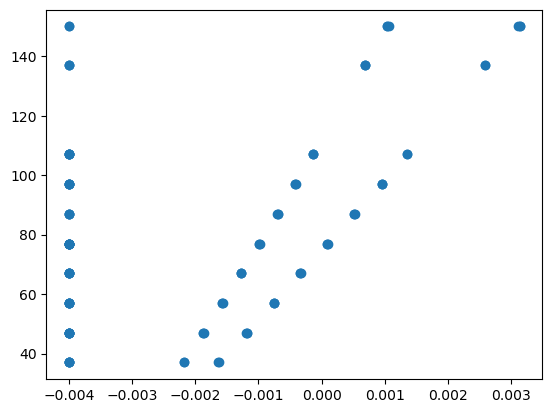

In [13]:
fig, ax  = plt.subplots()
ax.scatter(stored_currents, stored_frequencies)